In [32]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

In [33]:
# Load the dataset
df = pd.read_csv('../csv/clubs.csv')

print(df.dtypes)

# Display some rows of the dataset
df

club_id                      int64
club_code                   object
name                        object
domestic_competition_id     object
total_market_value         float64
squad_size                   int64
average_age                float64
foreigners_number            int64
foreigners_percentage      float64
national_team_players        int64
stadium_name                object
stadium_seats                int64
net_transfer_record         object
coach_name                 float64
last_season                  int64
url                         object
dtype: object


,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,url
0,105,sv-darmstadt-98,Sportverein Darmstadt 1898 e. V.,L1,NaN,30,26.4,11,36.7,1,Merck-Stadion am Böllenfalltor,17810,€-1.60m,NaN,2023,https://www.transfermarkt.co.uk/sv-darmstadt-9...
1,11127,ural-ekaterinburg,FK Ural Yekaterinburg,RU1,NaN,25,28.2,13,52.0,5,Yekaterinburg Arena,23000,€-770k,NaN,2023,https://www.transfermarkt.co.uk/ural-ekaterinb...
2,114,besiktas-istanbul,Beşiktaş Jimnastik Kulübü,TR1,NaN,32,27.4,16,50.0,13,Tüpraş Stadyumu,42590,€-14.50m,NaN,2023,https://www.transfermarkt.co.uk/besiktas-istan...
3,12,as-rom,Associazione Sportiva Roma,IT1,NaN,26,27.4,17,65.4,17,Olimpico di Roma,73261,+€65.20m,NaN,2023,https://www.transfermarkt.co.uk/as-rom/startse...
4,148,tottenham-hotspur,Tottenham Hotspur Football Club,GB1,NaN,29,26.2,21,72.4,22,Tottenham Hotspur Stadium,62062,€-130.40m,NaN,2023,https://www.transfermarkt.co.uk/tottenham-hots...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,68608,cf-os-belenenses,CF Os Belenenses,PO1,NaN,30,25.7,5,16.7,0,Estádio do Restelo,19980,+-0,NaN,2017,https://www.transfermarkt.co.uk/cf-os-belenens...
422,724,fc-volendam,Football Club Volendam,NL1,NaN,29,22.8,14,48.3,3,Kras Stadion,7384,+€1.80m,NaN,2023,https://www.transfermarkt.co.uk/fc-volendam/st...
423,800,atalanta-bergamo,Atalanta Bergamasca Calcio S.p.a.,IT1,NaN,25,27.2,17,68.0,15,Gewiss Stadium,21747,+€87.00m,NaN,2023,https://www.transfermarkt.co.uk/atalanta-berga...
424,979,moreirense-fc,Moreirense Futebol Clube,PO1,NaN,26,26.0,17,65.4,2,Estádio C. J. de Almeida Freitas,6153,€-2.05m,NaN,2023,https://www.transfermarkt.co.uk/moreirense-fc/...


## Data Exploration
The dataset contains 16 columns and 426 rows describing different football clubs. The columns are:
- `club_id`: The unique identifier of the club
- `club_code`: The code of the club
- `name`: The name of the club
- `domestic_competition`: The domestic competition in which the club participates
- `total_market_value`: The total market value of the club
- `squad_size`: The size of the squad
- `average_age`: The average age of the squad
- `foreign_number`: The number of foreign players in the squad
- `foreign_percentage`: The percentage of foreign players in the squad
- `national_team_players`: The number of players in the national team
- `stadium_name`: The name of the stadium
- `stadium_seats`: The number of seats in the stadium
- `net_transfer_record`: The net transfer record
- `coach_name`: The name of the coach
- `last_season`: The last season played
- `url`: url that contains more information about the club

### Data Cleaning

Number of duplicate rows =  0


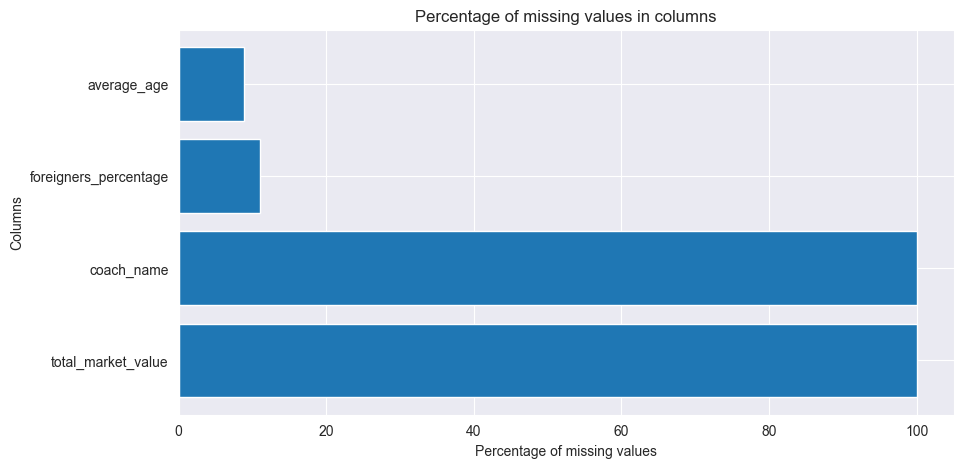

In [34]:
#check for duplicates
duplicates = df.duplicated().sum()
print('Number of duplicate rows = ', duplicates)

#mean of missing values per column
missing_values = df.isnull().mean() * 100

#filter columns with missing values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
plt.figure(figsize=(10, 5))
plt.barh(missing_values.index, missing_values)
plt.xlabel('Percentage of missing values')
plt.ylabel('Columns')
plt.title('Percentage of missing values in columns')
plt.show()

### Visualization of missing values
The plot above shows the percentage of missing values in columns. There is a percentage of missing values of 100% in the columns `total_market_value` and `coach_name`, we are going to drop these columns because they do not provide any useful information. The column `url` is also going to be dropped because it is not relevant for the analysis. <br>
The other columns `average_age` and `foreing_percentage` will be handled.

In [35]:
# Drop columns with missing values  
df = df.drop(columns=['total_market_value', 'coach_name', 'url'])

#filtering the columns with missing values to extract the unique values only in missing values
filtered_foreigners = df[df['foreigners_percentage'].isnull()]['foreigners_number']
unique_val_numbers = filtered_foreigners.unique()
    
if unique_val_numbers.item() == 0:
    #fill the missing values with 0
    df['foreigners_percentage'] = df['foreigners_percentage'].fillna(0)

#display the rows to see if the missing values were filled
df.query('foreigners_percentage.isnull()')

,club_id,club_code,name,domestic_competition_id,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,last_season


### Handling Missing Values in the DataFrame

In this section, we handled missing values, particularly in the `foreigners_percentage` column:

**Dropping Unnecessary Columns:**
   We drop the columns `total_market_value`, `coach_name`, and `url` from the DataFrame as they contain missing values, and we do not need them for our analysis.
   
We filled with the value 0 just the missing values where the percentage of foreigners is missing and the number of foreigners is 0.

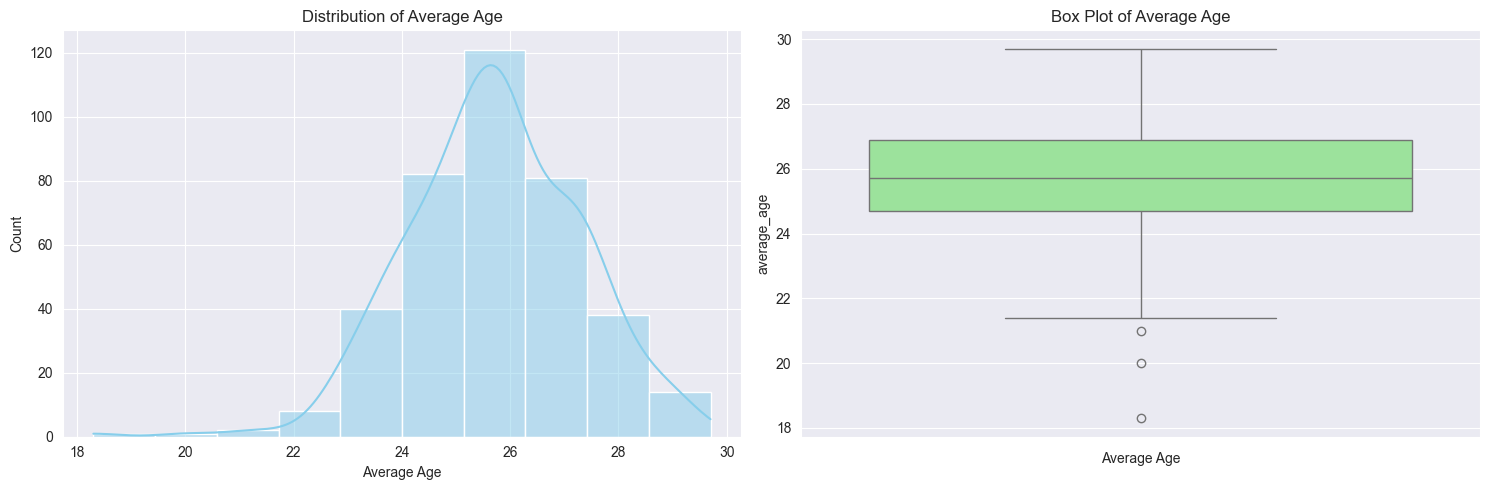

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Histogram of average age
sns.histplot(df['average_age'], bins=10, kde=True, color='skyblue', ax=ax[0])
ax[0].set_title('Distribution of Average Age')
ax[0].set_xlabel('Average Age')
ax[0].set_ylabel('Count')

# Box plot of average age
sns.boxplot(df['average_age'], color='lightgreen', ax=ax[1])
ax[1].set_title('Box Plot of Average Age')
ax[1].set_xlabel('Average Age')

plt.tight_layout()
plt.show()


### Distribution of Average Age
The histogram and box plot above show the distribution of the average age of the squads. The average age of the squads is approximately normally distributed with a mean around 25 years. <br>
We find some outliers in the box plot, with age mean of 19 years.

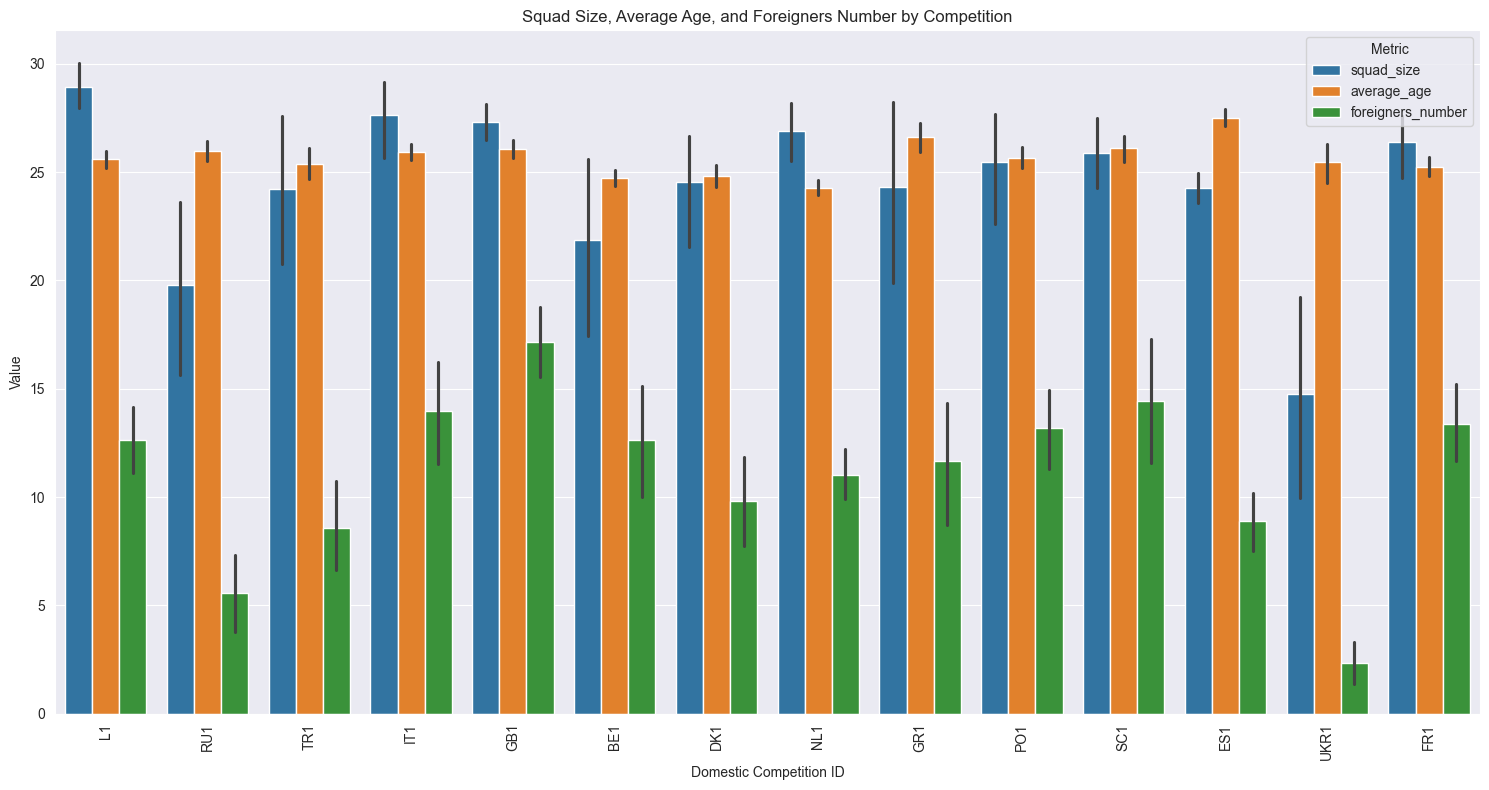

In [37]:
melted_df = pd.melt(df[['domestic_competition_id', 'squad_size', 'average_age', 'foreigners_number']],
                    id_vars='domestic_competition_id',
                    var_name='Metric',
                    value_name='Value')

# Plot the unified bar plot
plt.figure(figsize=(15, 8))
sns.barplot(x='domestic_competition_id', y='Value', hue='Metric', data=melted_df)
plt.title('Squad Size, Average Age, and Foreigners Number by Competition')
plt.xlabel('Domestic Competition ID')
plt.ylabel('Value')
plt.xticks(rotation=90)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Squad Size, Average Age, and Foreigners Number by Competition
The bar plot above shows the squad size, average age, and number of foreigners by domestic competition. The squad_number is not so different between the competitions, same thing for the average age.

**Squad size**
- Max: The maximum squad size is around 30 players, and it's reached by the competition L1.
- Min: The minimum squad size is around 15 players, and it's reached by the competition UKR1.<br>
    We can hypothesize that clubs in competitions L1 use more players during the season than clubs in competition UKR1.    

**Average age**
- Max: The maximum average age is around 27 years, and it's reached by the competition ES1.
- Min: The minimum average age is around 24 years, and it's reached by the competition NL1.<br>
    We can hypothesize that clubs in competition ES1 have older players than clubs in competition NL1.

**Number of foreigners**
- Max: The maximum number of foreigners is around 18 players, and it's reached by the competition GB1.
- Min: The minimum number of foreigners is around 2 players, and it's reached by the competition UKR1.<br>
    We can hypothesize that clubs in competition GB1 have more foreign players than clubs in competition UKR1.

Furthermore, the df doesn't contain much domestic competitions, and it's concentrated in the European region.

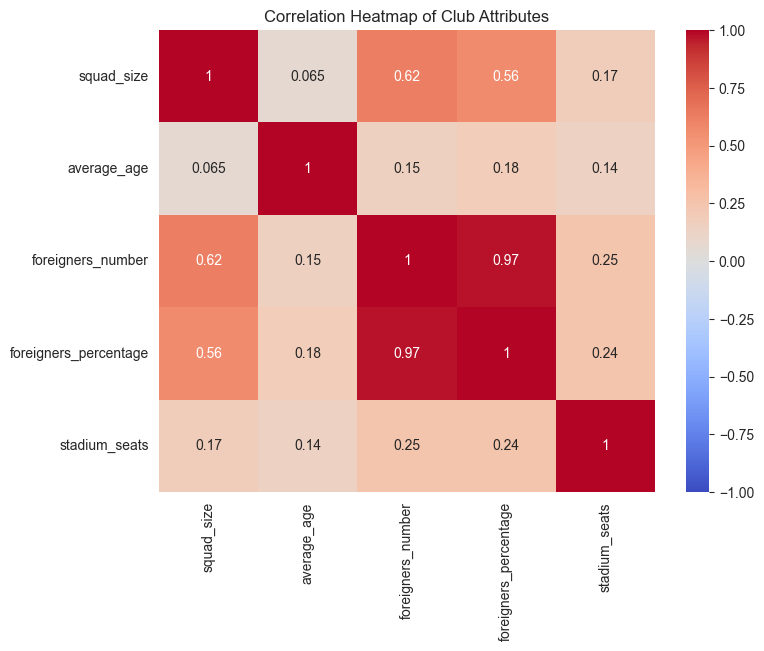

In [38]:
# Calculate the correlation matrix
correlation_matrix = df[['squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'stadium_seats']].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Club Attributes')
plt.show()


### Correlation Analysis Between Variables

This section presents the correlation values between different variables. The values indicate the strength and direction of the linear relationship between the pairs of variables.

#### Observations:

- **Squad Size and Foreigners Number (0.62)**: this value indicates that larger squads tend to have more foreign players.
- **Squad Size and Foreigners Percentage (0.56)**: similarly, a positive correlation exists between squad size and the percentage of foreign players, but it is slightly weaker compared to the number of foreign players.
- **Foreigners Number and Foreigners Percentage (0.97)**: there is an almost perfect positive correlation between the number of foreign players and the percentage of foreign players, as expected. 
- **Squad Size and Stadium Seats (0.17)**: there is a weak positive correlation between squad size and stadium capacity, suggesting that teams with larger squads tend to have slightly bigger stadiums, but the relationship is not strong
- **Average Age and Foreigners Number (0.15)**: a small positive correlation suggests that squads with older average ages tend to have slightly more foreign players.
- **Average Age and Foreigners Percentage (0.18)**: similarly, older squads tend to have a slightly higher percentage of foreign players.
- **Foreigners Number and Stadium Seats (0.25)**: a modest positive correlation suggests that clubs with larger stadiums tend to have more foreign players.
- **Foreigners Percentage and Stadium Seats (0.24)**: there is a weak positive correlation between the percentage of foreign players and the size of the stadium.

The correlation values provide insight into how certain club characteristics. A higher correlation (closer to 1 or -1) indicates a stronger relationship, while values closer to 0 indicate a weaker or no relationship.

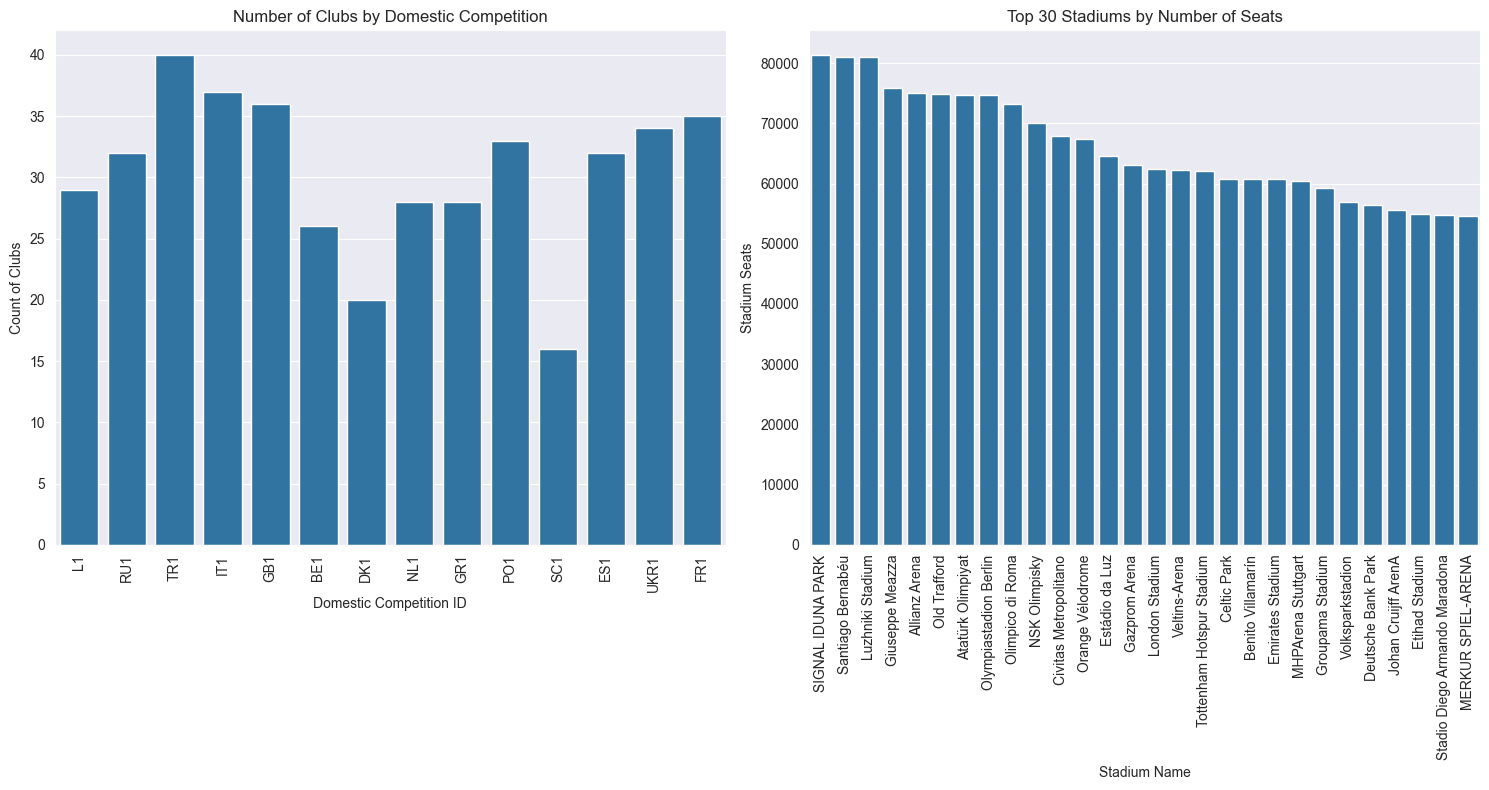

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))

# Count plot for number of clubs by domestic competition
sns.countplot(x='domestic_competition_id', data=df, ax=ax[0])
ax[0].set_title('Number of Clubs by Domestic Competition')
ax[0].set_xlabel('Domestic Competition ID')
ax[0].set_ylabel('Count of Clubs')
ax[0].tick_params(axis='x', rotation=90)

# Set the number of top stadiums to display
n = 30

# Sort the DataFrame by 'stadium_seats' in descending order and select the top n
top_stadiums = df.sort_values(by='stadium_seats', ascending=False).head(n)

# Create the bar plot for the top n stadiums
sns.barplot(x='stadium_name', y='stadium_seats', data=top_stadiums, ax=ax[1])
ax[1].set_title(f'Top {n} Stadiums by Number of Seats')
ax[1].set_xlabel('Stadium Name')
ax[1].set_ylabel('Stadium Seats')
ax[1].tick_params(axis='x', rotation=90)

# Adjust the layout for better spacing
plt.tight_layout()

# Display the plots
plt.show()

## Analysis of Number of Clubs by Domestic Competition and Top 30 Stadiums by Number of Seats

### Number of Clubs by Domestic Competition
The first bar plot compares the number of clubs participating in various domestic competitions, represented by their *Domestic Competition ID*. 

- *TR1* stands out as the competition with the most clubs, indicating either a larger league structure or potentially including lower-tier clubs.
- Other notable competitions, such as *IT1* (possibly Serie A) and *GB1* (Premier League), also have a relatively high number of participating clubs.
- In contrast, some leagues, such as *DK1* (Denmark) and *SC1* (Scotland), have fewer clubs. This suggests that these leagues operate with smaller pools of competition, which could reflect differences in the size of the football market in these countries or specific league policies regarding team participation.

This plot provides insights into how league structures vary between countries. For instance, larger leagues might have more financial resources or a larger fanbase, while smaller leagues may be more tightly contested due to the limited number of clubs.

### Top 30 Stadiums by Number of Seats
The second bar plot illustrates the top 30 football stadiums ranked by seating capacity, with *Signal Iduna Park* (home of Borussia Dortmund) and *Santiago Bernabéu* (Real Madrid's home ground) topping the list.

- The *largest stadiums* are concentrated in countries with rich football traditions, such as Germany, Spain, and Italy. This reflects not only the massive fanbases these clubs enjoy but also the commercial significance of these stadiums. Stadium capacity is often a direct indicator of a club's ability to generate matchday revenue, contributing significantly to their financial health.
- The distribution of stadium sizes reveals that after the top few stadiums (which hold around 80,000 spectators), the seating capacity gradually decreases. This shows that while a few elite clubs have monumental stadiums, many of the top football clubs operate with capacities in the 55,000 to 65,000 range, still large but more modest in comparison to the giants of world football.

It is also important to note the variety of clubs represented in this plot. Both long-standing traditional clubs and modern teams with relatively new stadiums feature on this list. The presence of *English Premier League* clubs like *Old Trafford* (Manchester United) and *Tottenham Hotspur Stadium* confirms the role of stadium infrastructure in maintaining elite club status.

These visualizations offer a deeper understanding of the structure of domestic competitions and the significance of stadium capacity within football's global hierarchy. Larger leagues and bigger stadiums often correlate with a club's financial power and cultural influence, which shapes their success both domestically and internationally.


In [40]:
# Save the cleaned dataset to a new CSV file
df.to_csv('../cleaned_csv/clubs_cleaned.csv', index=False)